# Projeto 1 – Modelação: Regressão
## Prever o tempo de internamento a partir das primeiras 24 h (Grupo 5)

Este notebook implementa a parte de **regressão** dos capítulos 5 (Modeling) e 6 (Evaluation) do relatório. Parte de `dataset_regressao.csv`, produzido pelo notebook **02_data_preparation**, e segue a estrutura do demo da aula (`demo reg.ipynb`): dividir os dados, treinar uma árvore e uma rede neuronal, prever e avaliar com MAE e RMSE.

Em relação ao demo, há três diferenças, todas impostas pelos nossos dados:

| Demo da aula | Este notebook | Porquê |
|---|---|---|
| Um split 70/30 | *Leave-one-out* (cada bebé é testado uma vez) e *k-fold* repetido | Só temos 47 bebés: um único split de 14 bebés de teste daria um MAE que muda muito com a sorte do sorteio |
| Dados sem normalização | `StandardScaler` dentro de um *pipeline* para Ridge e rede neuronal | As variáveis têm escalas muito diferentes (bpm, %, horas); o *pipeline* ajusta a escala só nos dados de treino |
| Alvo na escala original | Alvo também em log(1 + dias) | O internamento é assimétrico (assimetria 1,15, que passa a 0,06 em log) |

| Secção do relatório | O que este notebook faz |
|---|---|
| 5.1 Selecionar técnicas | Lista dos algoritmos e pressupostos |
| 5.2 Desenho de teste | Validação *leave-one-out*, métricas e *baseline* |
| 5.3 Construir modelos | Baseline, Ridge, árvore, Random Forest, Gradient Boosting, rede neuronal |
| 5.4 Avaliar modelos | Tabela comparativa, estabilidade, resíduos, variáveis mais importantes |
| 6.1 Avaliar resultados | Comparação com os critérios de sucesso da Tabela 8 |
| — | Modelo final treinado com os 47 bebés e guardado para o Projeto 2 |

## 0. Configuração

In [1]:
# --- Bibliotecas ---
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib                                   # guardar o modelo final (Projeto 2)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# --- Pastas (mesma lógica dos notebooks 01 e 02) ---
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC_DIR = ROOT / "data" / "processed"                      # saída do notebook 02
MODEL_DIR = ROOT / "models"                                  # modelos finais para o BI
FIG_DIR = ROOT / "reports" / "figures" / "modeling_regressao"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42                                                    # mesma semente em todo o lado (reprodutibilidade)

from sklearn.model_selection import LeaveOneOut, RepeatedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

## Carregar o conjunto de regressão

Uma linha por bebé. As variáveis explicativas descrevem só as **primeiras 24 h** (regra 4.1 do relatório). Ficam de fora:

- `episodio`: é um identificador, não uma característica do bebé;
- `los` e `log_los`: são o alvo;
- `cens_direita` e `cens_esquerda`: só se sabem no fim da recolha, por isso não existem no momento da previsão. Guardamo-las para analisar os erros.

In [2]:
d = pd.read_csv(PROC_DIR / "dataset_regressao.csv")
NAO_EXPLICATIVAS = ["episodio", "los", "log_los", "cens_direita", "cens_esquerda"]
X = d.drop(columns=NAO_EXPLICATIVAS)
y = d["los"].to_numpy()
print(f"{X.shape[0]} bebés x {X.shape[1]} variáveis explicativas")
print(f"Alvo: {y.min()} a {y.max()} dias, mediana {np.median(y):.0f}, média {y.mean():.1f}")
X.head()

47 bebés x 28 variáveis explicativas
Alvo: 2 a 37 dias, mediana 9, média 12.5


,hora_admissao,sat_o2_media,sat_o2_mediana,sat_o2_dp,sat_o2_min,sat_o2_max,puls_rate_media,puls_rate_mediana,puls_rate_dp,puls_rate_min,puls_rate_max,perfusion_media,perfusion_mediana,perfusion_dp,perfusion_min,perfusion_max,horas_registadas,pct_horas_sat_lt90,pct_horas_taquicardia,pct_horas_bradicardia,pct_horas_perf_baixa,pat_anemia_dia1,pat_cmv_dia1,pat_dbp_dia1,pat_dmh_dia1,pat_ictericia_dia1,pat_rge_dia1,n_patologias_dia1
0,9,93.6913,94.480,1.9720,90.00,96.50,159.0583,158.535,6.0535,148.50,169.00,0.9988,0.975,0.2850,0.49,1.64,24,0.0,0.0,0.0,16.6667,0,0,1,0,0,1,2
1,10,94.8383,94.850,2.0003,91.19,98.12,142.3017,140.550,6.8710,130.17,154.43,1.2150,1.225,0.2200,0.85,1.55,24,0.0,0.0,0.0,0.0000,0,0,0,0,0,0,0
2,11,98.4592,98.350,0.9672,96.83,99.82,155.0743,155.870,7.8519,136.67,170.00,0.6979,0.750,0.1559,0.39,0.89,24,0.0,0.0,0.0,45.8333,0,0,0,1,1,0,2
3,15,95.5324,95.450,1.1196,93.98,97.83,134.5553,136.170,8.0069,117.27,148.06,1.3172,1.265,0.4153,0.83,1.93,18,0.0,0.0,0.0,0.0000,0,0,0,0,0,0,0
4,1,97.5725,97.675,0.8214,95.73,99.00,119.1217,117.220,8.3042,103.80,134.60,1.5013,1.300,0.7001,0.65,3.51,24,0.0,0.0,0.0,8.6957,0,0,0,0,0,0,0


## 5.1 Selecionar técnicas de modelação

Seguimos a Tabela 13 do relatório: começar pelo mais simples e só subir de complexidade se compensar.

| Modelo | Tipo | Pressupostos / cuidados |
|---|---|---|
| *Baseline* (mediana do treino) | Referência | Nenhum: é o valor a bater |
| Ridge, alvo em log | Linear regularizado | Relação aproximadamente linear com log(dias); precisa de normalização |
| Árvore de decisão (como no demo) | Regras | Interpretável; com 47 bebés tem de ser pouco profunda para não decorar os dados |
| Random Forest, alvo em log | *Ensemble* de árvores | Robusta a escalas e a relações não lineares |
| Gradient Boosting (erro absoluto) | *Ensemble* sequencial | A função de perda é o próprio MAE, a nossa métrica principal |
| Rede neuronal (MLP, como no demo) | Não linear | Muito sensível à escala e ao tamanho; usamos uma rede pequena e muito regularizada |

O demo usa uma rede `[1024, 516, 256, 8]`. Com 47 bebés e 28 variáveis isso dá centenas de milhares de pesos para 46 exemplos de treino, por isso usamos uma única camada de 8 neurónios.

## 5.2 Gerar o desenho de teste

- **Validação:** *leave-one-out*. O modelo é treinado 47 vezes, sempre com 46 bebés, e prevê o bebé que ficou de fora. Assim, **cada previsão é feita num bebé que o modelo nunca viu**, e cada bebé conta uma vez no MAE final.
- **Robustez:** para os melhores modelos repetimos com *5-fold* repetido 10 vezes, para ver a variação do MAE entre partições.
- **Métricas:** MAE em dias (principal) e RMSE (penaliza mais os erros grandes).
- **Transformações dentro do pipeline:** a normalização e o logaritmo do alvo são ajustados em cada treino, nunca com o bebé de teste.

In [3]:
def log_alvo(modelo):
    # Treina em log(1 + dias) e devolve a previsão já em dias
    return TransformedTargetRegressor(regressor=modelo, func=np.log1p, inverse_func=np.expm1)

def avaliar_loo(modelo):
    # Uma previsão por bebé, feita sem esse bebé no treino
    prev = cross_val_predict(modelo, X, y, cv=LeaveOneOut(), n_jobs=-1)
    return prev, mean_absolute_error(y, prev), root_mean_squared_error(y, prev)

resultados, previsoes = [], {}
def registar(nome, modelo):
    prev, mae, rmse = avaliar_loo(modelo)
    previsoes[nome] = prev
    resultados.append({"modelo": nome, "MAE": round(mae, 2), "RMSE": round(rmse, 2)})
    print(f"{nome:<32} MAE = {mae:5.2f} dias | RMSE = {rmse:5.2f} dias")

## 5.3 Construir os modelos

### Baseline

Prever para cada bebé a mediana dos outros 46. Tem de dar o mesmo valor que o notebook 02.

In [4]:
registar("Baseline (mediana)", DummyRegressor(strategy="median"))
MAE_BASE = resultados[0]["MAE"]
RMSE_BASE = resultados[0]["RMSE"]
print(f"Meta relativa (25% abaixo do baseline): MAE <= {0.75 * MAE_BASE:.2f} dias")

Baseline (mediana)               MAE =  7.02 dias | RMSE = 10.00 dias
Meta relativa (25% abaixo do baseline): MAE <= 5.26 dias


### Ridge (alvo em log)

A força da regularização (`alpha`) é alta porque temos quase tantas variáveis como bebés. Com pouca regularização, uma regressão linear simples tem MAE pior do que o baseline.

In [5]:
for alpha in [10, 100]:
    registar(f"Ridge log (alpha={alpha})", log_alvo(make_pipeline(StandardScaler(), Ridge(alpha=alpha))))

Ridge log (alpha=10)             MAE =  7.08 dias | RMSE =  9.98 dias
Ridge log (alpha=100)            MAE =  6.90 dias | RMSE =  9.60 dias


### Árvore de decisão (como no demo)

O demo usa a árvore sem limites. Aqui isso significa uma folha por bebé, ou seja, a árvore decora o treino. Comparamos com uma árvore limitada a 3 níveis e com pelo menos 5 bebés por folha.

In [6]:
registar("Árvore sem limites (demo)", DecisionTreeRegressor(random_state=SEED))
registar("Árvore (prof. 3, folha >= 5)", DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=SEED))

Árvore sem limites (demo)        MAE =  8.85 dias | RMSE = 11.43 dias
Árvore (prof. 3, folha >= 5)     MAE =  7.18 dias | RMSE =  9.66 dias


### Random Forest e Gradient Boosting

In [7]:
registar("Random Forest", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED))
registar("Random Forest log", log_alvo(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED)))
registar("Gradient Boosting (erro absoluto)", GradientBoostingRegressor(
    loss="absolute_error", n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED))

Random Forest                    MAE =  6.99 dias | RMSE =  8.79 dias
Random Forest log                MAE =  6.43 dias | RMSE =  8.79 dias
Gradient Boosting (erro absoluto) MAE =  6.84 dias | RMSE =  9.02 dias


### Rede neuronal (MLP)

Uma camada de 8 neurónios e paragem antecipada desligada (com 46 bebés não há dados para separar validação). Testamos duas forças de regularização:

- com `alpha=1`, a rede sobreajusta: em alguns bebés a previsão em log sai muito alta e, ao voltar para dias, explode;
- com `alpha=10`, fica estável, mas não bate o baseline.

Com tão poucos bebés, a rede neuronal é o modelo menos indicado. Fica na comparação porque é um dos modelos do demo.

In [8]:
for alpha in [1, 10]:
    registar(f"Rede neuronal log [8] (alpha={alpha})", log_alvo(make_pipeline(
        StandardScaler(), MLPRegressor(hidden_layer_sizes=[8], alpha=alpha, max_iter=5000, random_state=SEED))))

Rede neuronal log [8] (alpha=1)  MAE = 14.74 dias | RMSE = 47.10 dias
Rede neuronal log [8] (alpha=10) MAE =  7.11 dias | RMSE = 10.17 dias


## 5.4 Avaliar os modelos

### Tabela comparativa (Tabela 29 do relatório)

`melhoria_vs_baseline` é a redução do MAE em relação ao baseline. A meta da Tabela 8 é pelo menos 25%.

,modelo,MAE,RMSE,melhoria_vs_baseline_%
0,Random Forest log,6.43,8.79,8.4
1,Gradient Boosting (erro absoluto),6.84,9.02,2.6
2,Ridge log (alpha=100),6.90,9.60,1.7
3,Random Forest,6.99,8.79,0.4
4,Baseline (mediana),7.02,10.00,0.0
5,Ridge log (alpha=10),7.08,9.98,-0.9
6,Rede neuronal log [8] (alpha=10),7.11,10.17,-1.3
7,"Árvore (prof. 3, folha >= 5)",7.18,9.66,-2.3
8,Árvore sem limites (demo),8.85,11.43,-26.1
9,Rede neuronal log [8] (alpha=1),14.74,47.10,-110.0


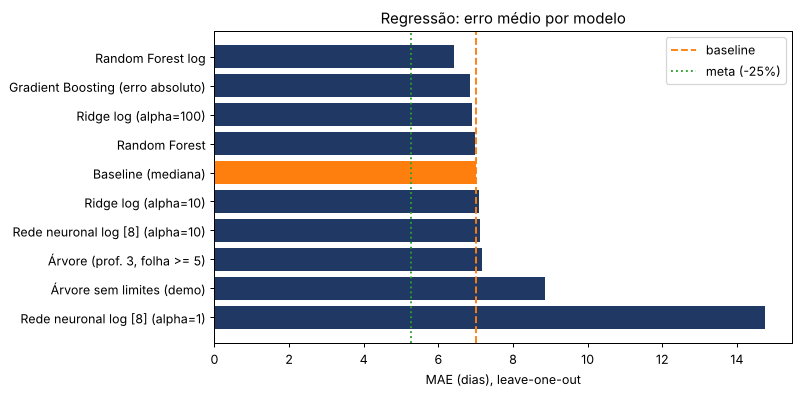

In [9]:
tabela = pd.DataFrame(resultados)
tabela["melhoria_vs_baseline_%"] = ((1 - tabela["MAE"] / MAE_BASE) * 100).round(1)
tabela = tabela.sort_values("MAE").reset_index(drop=True)
display(tabela)
tabela.to_csv(FIG_DIR / "tabela_regressao.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
cores = ["tab:orange" if m.startswith("Baseline") else "#1f3864" for m in tabela["modelo"]]
ax.barh(tabela["modelo"], tabela["MAE"], color=cores)
ax.axvline(MAE_BASE, color="tab:orange", ls="--", label="baseline")
ax.axvline(0.75 * MAE_BASE, color="tab:green", ls=":", label="meta (-25%)")
ax.invert_yaxis()
ax.set(xlabel="MAE (dias), leave-one-out", title="Regressão: erro médio por modelo")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "figura_mae_modelos.png", dpi=200, bbox_inches="tight")
plt.show()

### Estabilidade: *5-fold* repetido 10 vezes

Com 47 bebés, uma diferença de poucas décimas de dia entre modelos pode ser só ruído. Repetimos a validação com 10 partições diferentes para os três melhores modelos e para o baseline, e vemos a média e o desvio-padrão do MAE.

In [10]:
def mae_repetido(modelo, repeticoes=10):
    maes = []
    for tr, ts in RepeatedKFold(n_splits=5, n_repeats=repeticoes, random_state=SEED).split(X):
        modelo.fit(X.iloc[tr], y[tr])
        maes.append(mean_absolute_error(y[ts], modelo.predict(X.iloc[ts])))
    return np.mean(maes), np.std(maes)

candidatos = {
    "Baseline (mediana)": DummyRegressor(strategy="median"),
    "Random Forest log": log_alvo(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting (erro absoluto)": GradientBoostingRegressor(
        loss="absolute_error", n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED),
    "Ridge log (alpha=100)": log_alvo(make_pipeline(StandardScaler(), Ridge(alpha=100))),
}
estab = pd.DataFrame([(n, *mae_repetido(m)) for n, m in candidatos.items()], columns=["modelo", "MAE_medio", "MAE_dp"]).round(2)
estab

,modelo,MAE_medio,MAE_dp
0,Baseline (mediana),6.87,2.04
1,Random Forest log,6.47,1.68
2,Gradient Boosting (erro absoluto),6.81,1.60
3,Ridge log (alpha=100),6.95,1.88


### Modelo escolhido

Escolhemos o **Random Forest com o alvo em log**: tem o menor MAE e o menor RMSE em *leave-one-out*, e mantém-se entre os melhores no *k-fold* repetido. A seguir vemos onde erra.

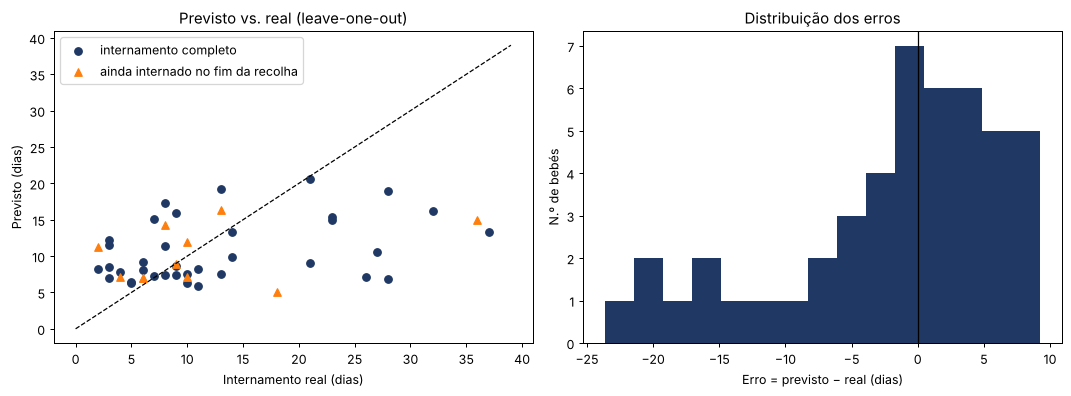

Bebés com erro <= 3 dias: 16 de 47
MAE nos internamentos <= 9 dias: 4.01 | > 9 dias: 8.95
MAE nos bebés ainda internados no fim da recolha: 5.70 (o real é só um limite inferior)


In [11]:
NOME_FINAL = "Random Forest log"
prev = previsoes[NOME_FINAL]
erro = prev - y

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cens = d["cens_direita"] == 1
axes[0].scatter(y[~cens], prev[~cens], color="#1f3864", label="internamento completo")
axes[0].scatter(y[cens], prev[cens], color="tab:orange", marker="^", label="ainda internado no fim da recolha")
lim = [0, y.max() + 2]
axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set(xlabel="Internamento real (dias)", ylabel="Previsto (dias)", title="Previsto vs. real (leave-one-out)")
axes[0].legend()
axes[1].hist(erro, bins=15, color="#1f3864")
axes[1].axvline(0, color="k", lw=1)
axes[1].set(xlabel="Erro = previsto − real (dias)", ylabel="N.º de bebés", title="Distribuição dos erros")
fig.tight_layout()
fig.savefig(FIG_DIR / "figura_residuos.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Bebés com erro <= 3 dias: {(np.abs(erro) <= 3).sum()} de {len(y)}")
print(f"MAE nos internamentos <= 9 dias: {np.abs(erro[y <= 9]).mean():.2f} | > 9 dias: {np.abs(erro[y > 9]).mean():.2f}")
print(f"MAE nos bebés ainda internados no fim da recolha: {np.abs(erro[cens]).mean():.2f} (o real é só um limite inferior)")

### Variáveis mais importantes

Usamos a **importância por permutação**: baralha-se uma variável de cada vez e mede-se quanto o MAE piora. Ao contrário da importância interna do Random Forest, não favorece variáveis com muitos valores diferentes. É calculada com o modelo treinado nos 47 bebés, por isso indica o que o modelo usa, não o que generaliza.

,variavel,aumento_MAE,dp
12,perfusion_mediana,2.327,0.371
14,perfusion_min,0.543,0.106
0,hora_admissao,0.502,0.133
11,perfusion_media,0.491,0.110
5,sat_o2_max,0.387,0.073
13,perfusion_dp,0.385,0.093
8,puls_rate_dp,0.374,0.067
15,perfusion_max,0.348,0.087
9,puls_rate_min,0.167,0.053
4,sat_o2_min,0.151,0.039


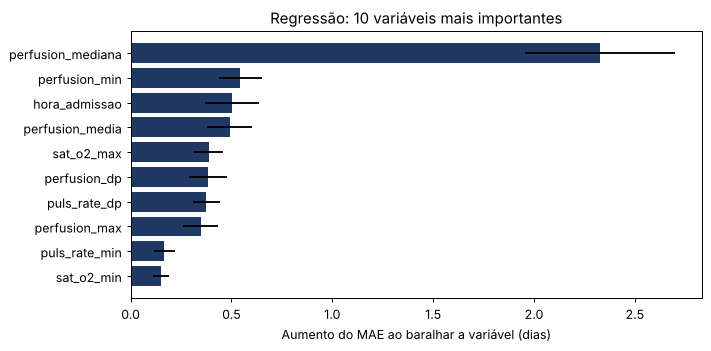

In [12]:
modelo_final = log_alvo(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1))
modelo_final.fit(X, y)

imp = permutation_importance(modelo_final, X, y, scoring="neg_mean_absolute_error", n_repeats=20, random_state=SEED)
importancias = (pd.DataFrame({"variavel": X.columns, "aumento_MAE": imp.importances_mean, "dp": imp.importances_std})
                .sort_values("aumento_MAE", ascending=False).head(10).round(3))
display(importancias)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importancias["variavel"], importancias["aumento_MAE"], xerr=importancias["dp"], color="#1f3864")
ax.invert_yaxis()
ax.set(xlabel="Aumento do MAE ao baralhar a variável (dias)", title="Regressão: 10 variáveis mais importantes")
fig.tight_layout()
fig.savefig(FIG_DIR / "figura_importancia.png", dpi=200, bbox_inches="tight")
plt.show()

### Árvore de decisão para interpretação

O Random Forest não se consegue desenhar. Para o relatório e para a enfermeira-chefe, mostramos a árvore de 3 níveis (secção 5.3) treinada nos 47 bebés: dá regras simples, mesmo sendo menos precisa.

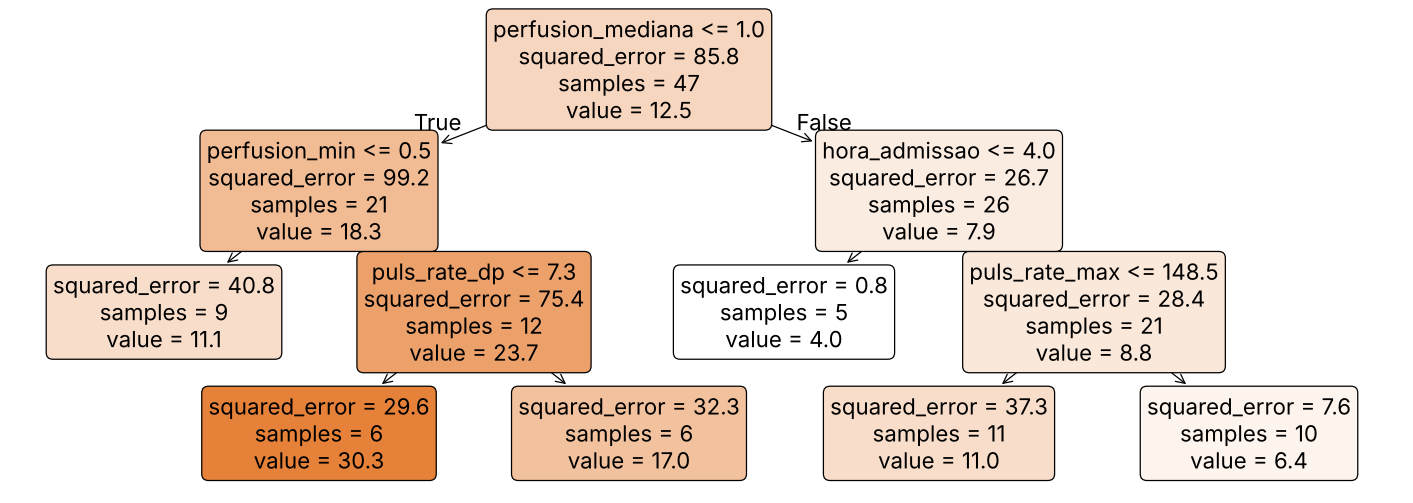

In [13]:
arvore = DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=SEED).fit(X, y)
plt.figure(figsize=(20, 7))
plot_tree(arvore, feature_names=X.columns, filled=True, rounded=True, precision=1)
plt.savefig(FIG_DIR / "figura_arvore_regressao.png", dpi=200, bbox_inches="tight")
plt.show()

## 6.1 Avaliar os resultados face aos critérios de sucesso (Tabela 8)

In [14]:
mae_f = tabela.set_index("modelo").loc[NOME_FINAL, "MAE"]
rmse_f = tabela.set_index("modelo").loc[NOME_FINAL, "RMSE"]
criterios = pd.DataFrame([
    ("MAE <= 6 dias (meta absoluta)", f"{mae_f:.2f}", mae_f <= 6),
    (f"MAE pelo menos 25% abaixo do baseline (<= {0.75 * MAE_BASE:.2f})", f"{mae_f:.2f}", mae_f <= 0.75 * MAE_BASE),
    (f"RMSE abaixo do baseline ({RMSE_BASE:.2f})", f"{rmse_f:.2f}", rmse_f < RMSE_BASE),
], columns=["critério", "valor obtido", "cumprido"])
criterios["cumprido"] = criterios["cumprido"].map({True: "✔", False: "✘"})
criterios

,critério,valor obtido,cumprido
0,MAE <= 6 dias (meta absoluta),6.43,✘
1,MAE pelo menos 25% abaixo do baseline (<= 5.26),6.43,✘
2,RMSE abaixo do baseline (10.00),8.79,✔


**Leitura dos resultados (para o capítulo 6):**

- O melhor modelo melhora o baseline, mas pouco: a meta de 25% não é atingida. O RMSE desce mais do que o MAE, ou seja, o modelo ajuda sobretudo a evitar os erros grandes.
- As primeiras 24 h têm pouca informação sobre a duração total, e 11 dos 47 internamentos estão cortados no fim da recolha, por isso o alvo verdadeiro é maior do que o registado.
- Melhorias possíveis, por ordem de custo: alargar a janela para 48 h (alterar `JANELA_REGRESSAO` no 02), reduzir as variáveis às mais importantes, tratar os internamentos cortados com modelos de sobrevivência.
- Os hiperparâmetros foram fixados à mão, sem pesquisa. Com 47 bebés, escolher hiperparâmetros pelo mesmo *leave-one-out* daria uma estimativa otimista; uma pesquisa honesta exige validação aninhada.

## Guardar o modelo final (para o Projeto 2)

O modelo treinado com os 47 bebés é guardado com a lista de variáveis, pela ordem certa, para o componente analítico do BI o poder usar sem refazer o treino.

In [15]:
joblib.dump({"modelo": modelo_final, "variaveis": list(X.columns), "alvo": "los (dias)",
             "mae_loo": mae_f, "rmse_loo": rmse_f}, MODEL_DIR / "modelo_regressao.joblib")

pd.DataFrame({"episodio": d["episodio"], "los_real": y, "los_previsto_loo": prev.round(1)}).to_csv(
    PROC_DIR / "previsoes_regressao.csv", index=False)
print("Guardado:", MODEL_DIR / "modelo_regressao.joblib")
print("Guardado:", PROC_DIR / "previsoes_regressao.csv")

Guardado: /home/claude/proj/models/modelo_regressao.joblib
Guardado: /home/claude/proj/data/processed/previsoes_regressao.csv
